# LPG Price Prediction Project
This notebook contains a complete data science workflow to predict LPG prices. We will perform data preprocessing, Exploratory Data Analysis (EDA), model training (Multi-Target Regression), feature selection, and model evaluation using visualizations like Parity Plots, Residual Plots, and SHAP Summary Plots.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import shap
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

## 1. Data Loading
We load the `lpg_prediction_data.csv` dataset.

In [3]:
df = pd.read_csv('lpg_prediction_data.csv')
display(df.head())

,state,region,year,month,5kg_price,12.5kg_price,pms_price,crude_oil_price,buying_rate,selling_rate,inflation_rate,conflict,festive_period
0,Abuja,North Central,2023,1,4840.000000,10135.000000,229.000000,84.78,454.446667,455.494286,21.82,No,Yes
1,Benue,North Central,2023,1,4886.666667,11260.666667,202.500000,84.78,454.446667,455.494286,21.82,No,Yes
2,Kogi,North Central,2023,1,4785.000000,10220.000000,236.538462,84.78,454.446667,455.494286,21.82,No,Yes
3,Kwara,North Central,2023,1,4962.500000,10400.000000,229.375000,84.78,454.446667,455.494286,21.82,No,Yes
4,Nasarawa,North Central,2023,1,4670.000000,10019.166667,217.500000,84.78,454.446667,455.494286,21.82,No,Yes


## 2. Data Preprocessing
As per requirements:
1. Calculate the 1kg price from 5kg and 12.5kg prices, and take their average to create `lpg_price_per_kg`.
2. Average `buying_rate` and `selling_rate` to create `dollar_price`.
We'll also encode categorical features (`state`, `region`, `conflict`, `festive_period`).

In [4]:
# Calculate 1kg price from 5kg and 12.5kg prices
price_1kg_from_5 = df['5kg_price'] / 5
price_1kg_from_12_5 = df['12.5kg_price'] / 12.5

# Average them to create lpg_price_per_kg
df['lpg_price_per_kg'] = (price_1kg_from_5 + price_1kg_from_12_5) / 2

# Create dollar_price
df['dollar_price'] = (df['buying_rate'] + df['selling_rate']) / 2

# Drop original buying_rate and selling_rate to avoid multicollinearity
df = df.drop(['buying_rate', 'selling_rate'], axis=1)

# Encode Categorical Variables
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['conflict'] = le.fit_transform(df['conflict'])
df['festive_period'] = le.fit_transform(df['festive_period'])
categorical_cols = ['state', 'region']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

display(df_encoded.head())

,year,month,5kg_price,12.5kg_price,pms_price,crude_oil_price,inflation_rate,conflict,festive_period,lpg_price_per_kg,...,state_Rivers,state_Sokoto,state_Taraba,state_Yobe,state_Zamfara,region_North East,region_North West,region_South East,region_South South,region_South West
0,2023,1,4840.000000,10135.000000,229.000000,84.78,21.82,0,1,889.400000,...,False,False,False,False,False,False,False,False,False,False
1,2023,1,4886.666667,11260.666667,202.500000,84.78,21.82,0,1,939.093333,...,False,False,False,False,False,False,False,False,False,False
2,2023,1,4785.000000,10220.000000,236.538462,84.78,21.82,0,1,887.300000,...,False,False,False,False,False,False,False,False,False,False
3,2023,1,4962.500000,10400.000000,229.375000,84.78,21.82,0,1,912.250000,...,False,False,False,False,False,False,False,False,False,False
4,2023,1,4670.000000,10019.166667,217.500000,84.78,21.82,0,1,867.766667,...,False,False,False,False,False,False,False,False,False,False


## 3. Exploratory Data Analysis (EDA)
Let's explore the data distributions and correlations.

In [5]:
# Summary statistics
display(df.describe())

,year,month,5kg_price,12.5kg_price,pms_price,crude_oil_price,inflation_rate,conflict,festive_period,lpg_price_per_kg,dollar_price
count,1369.000000,1369.000000,1369.000000,1369.000000,1369.000000,1369.000000,1369.000000,1369.000000,1369.000000,1369.000000,1369.000000
mean,2024.135135,6.108108,6183.420301,14909.435924,848.223184,81.620811,26.219189,0.351351,0.351351,1214.719467,1213.130136
std,0.963516,3.408581,1458.510188,4058.525602,345.749161,11.754044,5.660615,0.477567,0.477567,305.260044,423.589613
min,2023.000000,1.000000,3285.000000,7500.000000,191.428571,65.220000,15.060000,0.000000,0.000000,690.296905,454.970476
25%,2023.000000,3.000000,4822.750000,10550.550000,630.000000,74.440000,22.220000,0.000000,0.000000,897.835200,796.438000
50%,2024.000000,6.000000,6457.166667,15781.250000,871.887727,80.760000,26.270000,0.000000,0.000000,1280.533333,1459.040605
75%,2025.000000,9.000000,7190.000000,17660.230000,1083.400000,86.080000,31.700000,1.000000,1.000000,1422.534188,1535.444541
max,2026.000000,12.000000,9745.101279,25596.712609,1730.000000,126.710000,34.800000,1.000000,1.000000,1949.020256,1670.276429


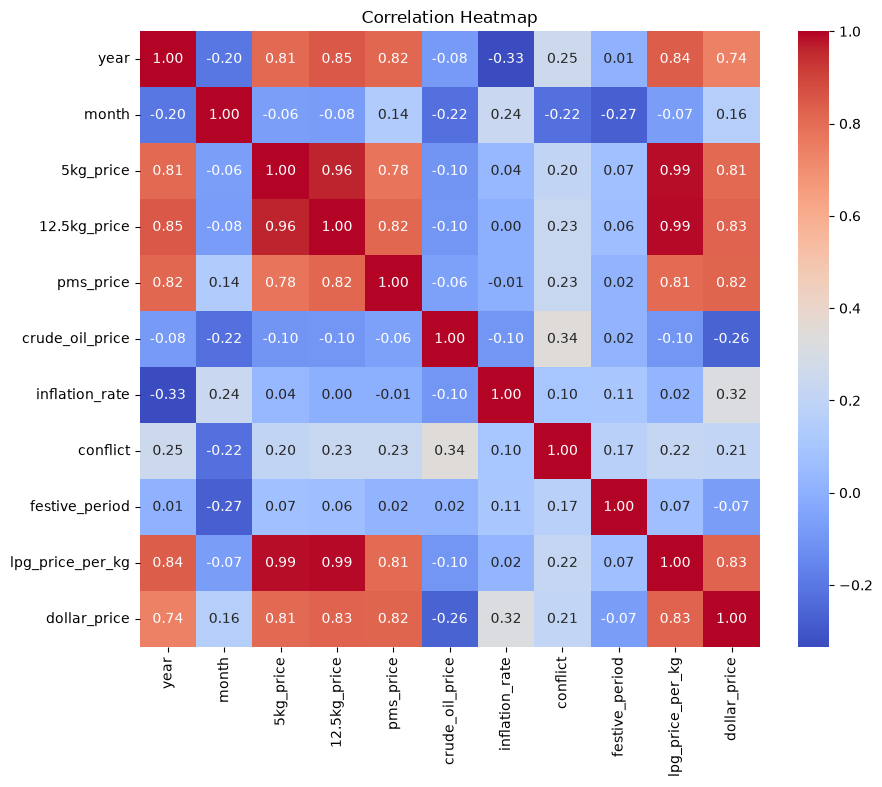

In [6]:
# Correlation Heatmap
plt.figure(figsize=(10, 8))
# Compute correlation for numeric columns only
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

We also inspect the effect of the `conflict` and `festive_period` features on LPG prices and crude oil prices.

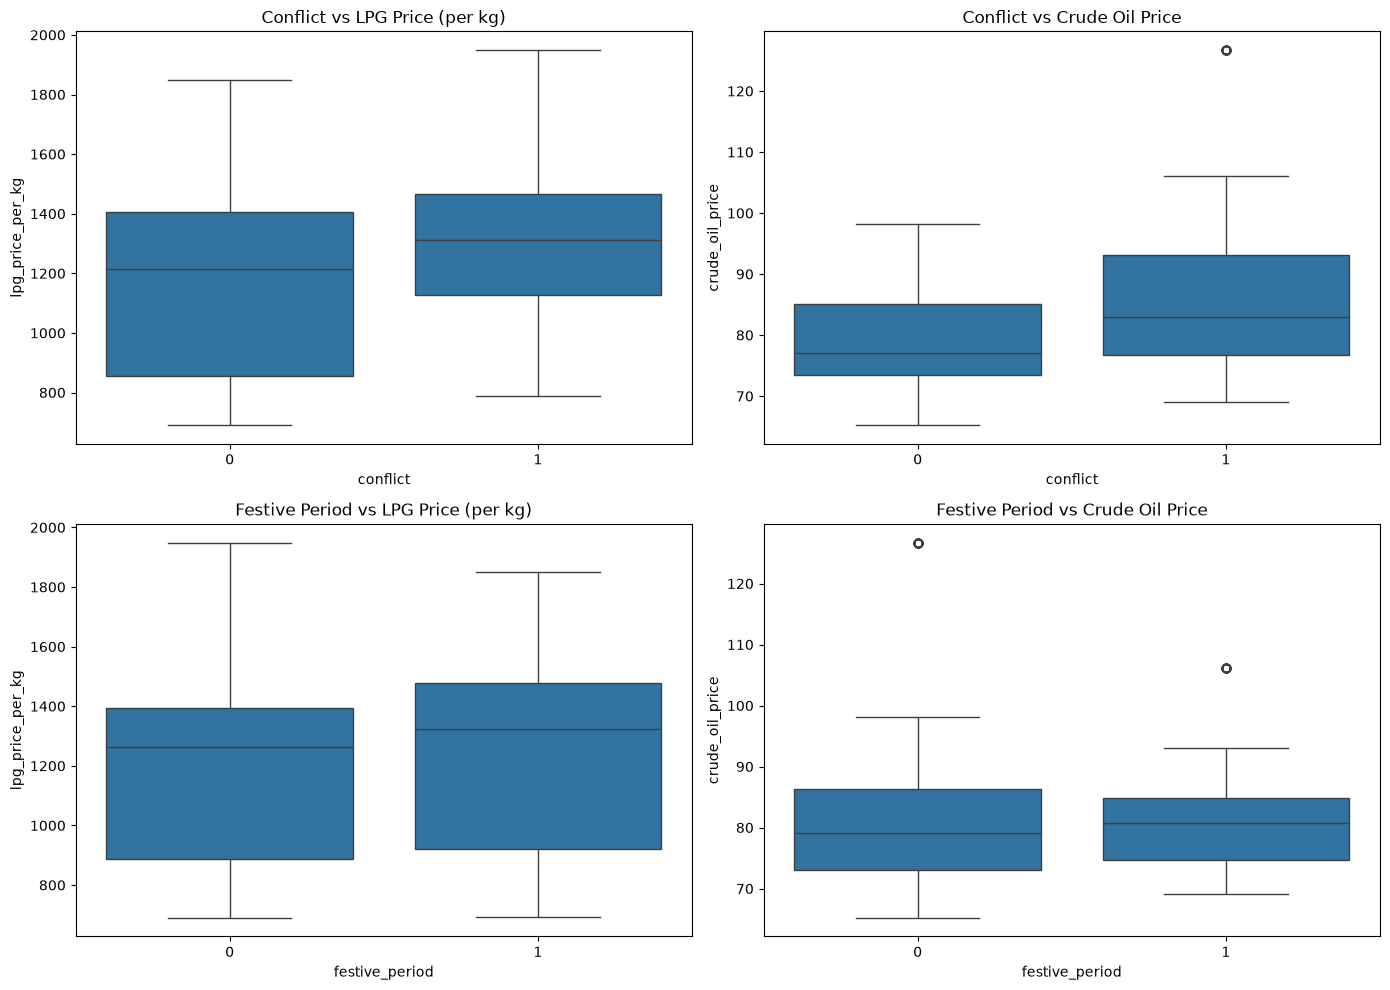

In [7]:
# Impact of Conflict and Festive Period on Prices
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(x='conflict', y='lpg_price_per_kg', data=df, ax=axes[0,0])
axes[0,0].set_title('Conflict vs LPG Price (per kg)')

sns.boxplot(x='conflict', y='crude_oil_price', data=df, ax=axes[0,1])
axes[0,1].set_title('Conflict vs Crude Oil Price')

sns.boxplot(x='festive_period', y='lpg_price_per_kg', data=df, ax=axes[1,0])
axes[1,0].set_title('Festive Period vs LPG Price (per kg)')

sns.boxplot(x='festive_period', y='crude_oil_price', data=df, ax=axes[1,1])
axes[1,1].set_title('Festive Period vs Crude Oil Price')

plt.tight_layout()
plt.show()

### Macro Trends: Monthly Average Dollar Price & PMS Price vs LPG Price
To inspect macro-level relationships across time, we calculate the average `dollar_price`, `pms_price`, and `lpg_price_per_kg` for each unique (`year`, `month`) pair and plot them in separate scatter plots.

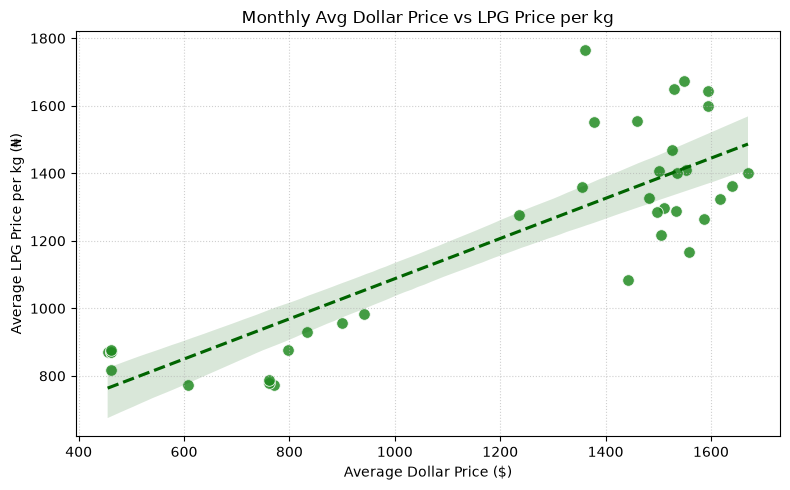

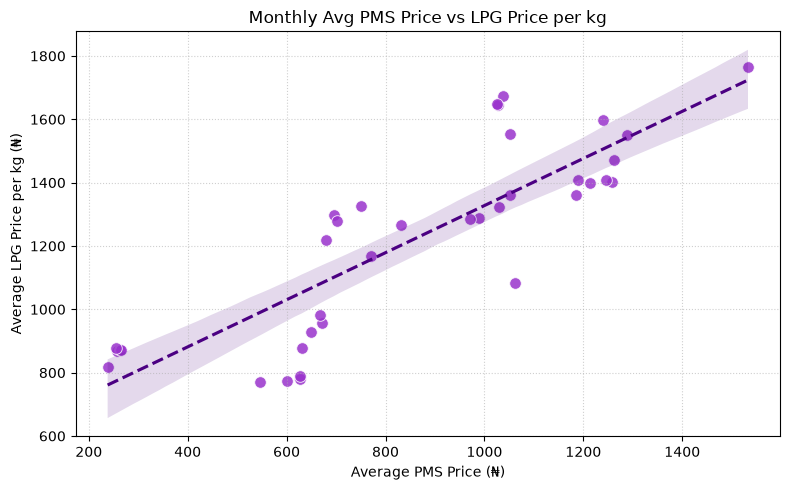

In [8]:
# Aggregate monthly/yearly averages across the dataset
monthly_avg = df.groupby(['year', 'month'])[['dollar_price', 'pms_price', 'lpg_price_per_kg']].mean().reset_index()

# 1. Scatter Plot: Monthly Average Dollar Price vs LPG Price per kg
plt.figure(figsize=(8, 5))
sns.scatterplot(data=monthly_avg, x='dollar_price', y='lpg_price_per_kg', color='forestgreen', s=70, alpha=0.85)
sns.regplot(data=monthly_avg, x='dollar_price', y='lpg_price_per_kg', scatter=False, color='darkgreen', line_kws={'linestyle': '--'})
plt.title('Monthly Avg Dollar Price vs LPG Price per kg')
plt.xlabel('Average Dollar Price ($)')
plt.ylabel('Average LPG Price per kg (₦)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Scatter Plot: Monthly Average PMS Price vs LPG Price per kg
plt.figure(figsize=(8, 5))
sns.scatterplot(data=monthly_avg, x='pms_price', y='lpg_price_per_kg', color='darkorchid', s=70, alpha=0.85)
sns.regplot(data=monthly_avg, x='pms_price', y='lpg_price_per_kg', scatter=False, color='indigo', line_kws={'linestyle': '--'})
plt.title('Monthly Avg PMS Price vs LPG Price per kg')
plt.xlabel('Average PMS Price (₦)')
plt.ylabel('Average LPG Price per kg (₦)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 4. Modeling (Multi-Target Regression)
The target variables are `lpg_price_per_kg`, `5kg_price`, and `12.5kg_price`.
We will split the data into 80/20 train/test sets and evaluate multiple models using K-Fold cross-validation.

In [9]:
target_cols = ['lpg_price_per_kg', '5kg_price', '12.5kg_price']
X = df_encoded.drop(target_cols, axis=1)
y = df_encoded[target_cols]

# 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(random_state=42, n_estimators=100),
    'XGBoost': XGBRegressor(random_state=42, objective='reg:squarederror')
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate Models
results = {}
for name, model in models.items():
    if name != 'Linear Regression' and name != 'Random Forest':
        model = MultiOutputRegressor(model)
    cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_mean_squared_error')
    rmse_scores = np.sqrt(-cv_scores)
    results[name] = np.mean(rmse_scores)
    print(f'{name} Average RMSE across all targets: {results[name]:.4f}')

best_model_name = min(results, key=results.get)
print(f'\nBest Model: {best_model_name}')

Linear Regression Average RMSE across all targets: 1081.3566
Random Forest Average RMSE across all targets: 522.5959
XGBoost Average RMSE across all targets: 522.9533

Best Model: Random Forest


## 5. Model Refinement & Geographical Ablation Study
We will create four variants of feature sets to test the impact of `state` and `region` dummy variables. We will train the best algorithm on four variants and select the one with the highest average R-squared.

In [10]:
import copy

best_model_base = models[best_model_name]
if best_model_name != 'Linear Regression' and best_model_name != 'Random Forest':
    base_estimator = MultiOutputRegressor(best_model_base)
else:
    base_estimator = best_model_base

# Define the four feature sets
state_cols = [c for c in X.columns if c.startswith('state_')]
region_cols = [c for c in X.columns if c.startswith('region_')]

# i. All features
set_1 = X_train.columns.tolist()
# ii. All features without state and region dummies
set_2 = [c for c in X_train.columns if c not in state_cols and c not in region_cols]
# iii. All features including state dummies removing region dummies
set_3 = [c for c in X_train.columns if c not in region_cols]
# iv. All features including region dummies removing state dummies
set_4 = [c for c in X_train.columns if c not in state_cols]

variants = {
    'Variant 1 (All features)': set_1,
    'Variant 2 (No State, No Region)': set_2,
    'Variant 3 (With State, No Region)': set_3,
    'Variant 4 (With Region, No State)': set_4
}

best_r2_avg = -float('inf')
best_variant_name = ''
best_variant_features = []

print('--- Geographical Feature Ablation Study ---')
for v_name, v_features in variants.items():
    X_tr = X_train[v_features]
    X_te = X_test[v_features]
    
    model = copy.deepcopy(base_estimator)
    model.fit(X_tr, y_train)
    y_p = model.predict(X_te)
    
    r2_scores = []
    for i, col in enumerate(target_cols):
        r2_scores.append(r2_score(y_test.iloc[:, i], y_p[:, i]))
    
    avg_r2 = np.mean(r2_scores)
    print(f'{v_name} | Avg R2: {avg_r2:.4f}')
    
    if avg_r2 > best_r2_avg:
        best_r2_avg = avg_r2
        best_variant_name = v_name
        best_variant_features = v_features

print(f'\\nSelected Best Variant: {best_variant_name} with Avg R2: {best_r2_avg:.4f}')

# Set X_train_sel and X_test_sel for the rest of the notebook (Plots etc.)
X_train_sel = X_train[best_variant_features]
X_test_sel = X_test[best_variant_features]

final_model = copy.deepcopy(base_estimator)
final_model.fit(X_train_sel, y_train)
y_pred = final_model.predict(X_test_sel)

print('\\nFinal Model Performance on Test Set:')
for i, col in enumerate(target_cols):
    r2 = r2_score(y_test.iloc[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_test.iloc[:, i], y_pred[:, i]))
    print(f'Target: {col} | R2: {r2:.4f} | RMSE: {rmse:.4f}')

# We still want feature_importance_df for the bar chart
if hasattr(final_model, 'feature_importances_'):
    importances = final_model.feature_importances_
elif hasattr(final_model, 'estimators_'):
    importances = np.mean([est.feature_importances_ if hasattr(est, 'feature_importances_') else np.zeros(X_train_sel.shape[1]) for est in final_model.estimators_], axis=0)
else:
    importances = np.mean(np.abs(final_model.coef_), axis=0)

feature_importance_df = pd.DataFrame({
    'Feature': X_train_sel.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

--- Geographical Feature Ablation Study ---
Variant 1 (All features) | Avg R2: 0.9488
Variant 2 (No State, No Region) | Avg R2: 0.9205
Variant 3 (With State, No Region) | Avg R2: 0.9391
Variant 4 (With Region, No State) | Avg R2: 0.9393
\nSelected Best Variant: Variant 1 (All features) with Avg R2: 0.9488
\nFinal Model Performance on Test Set:
Target: lpg_price_per_kg | R2: 0.9555 | RMSE: 65.3299
Target: 5kg_price | R2: 0.9385 | RMSE: 364.0133
Target: 12.5kg_price | R2: 0.9525 | RMSE: 901.7153


## 6. Plot Generation
We will create Parity plots, Residual plots, and Feature Importance bar charts. All plots will be saved to the `plot_images` folder.

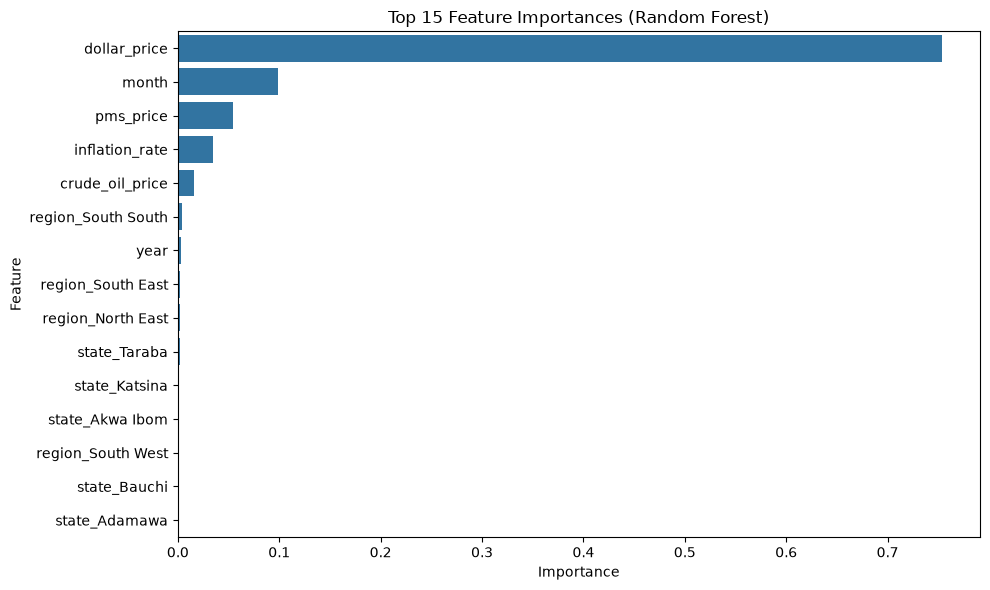

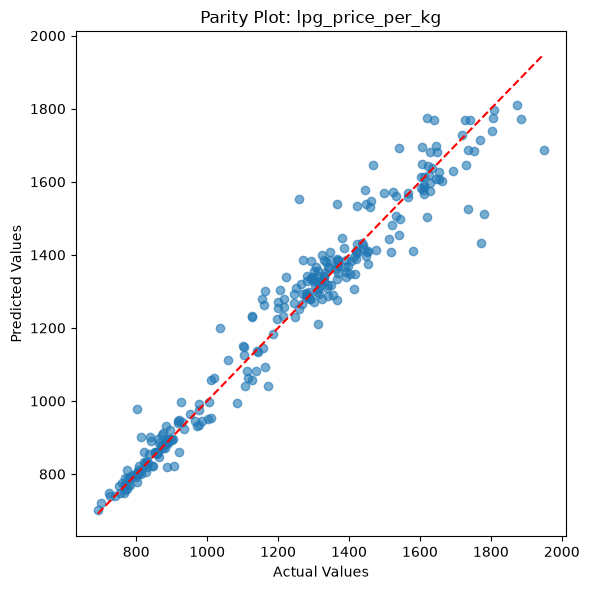

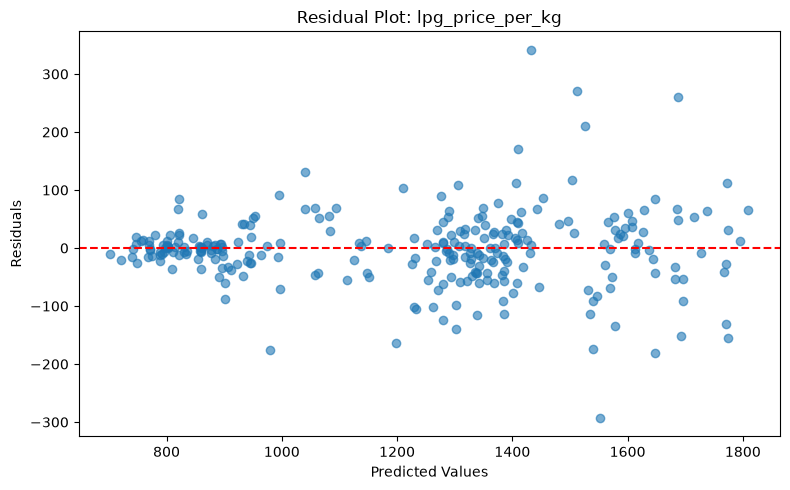

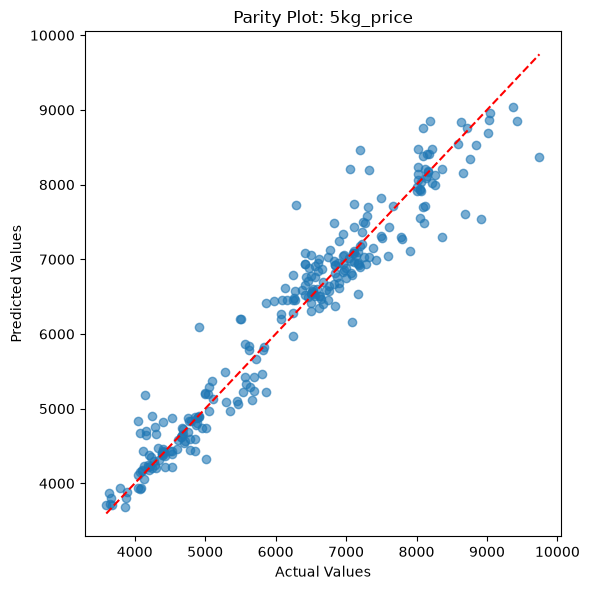

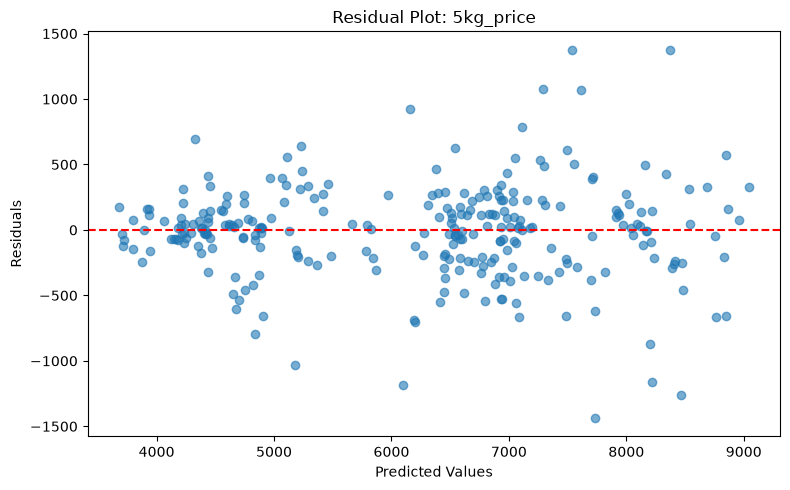

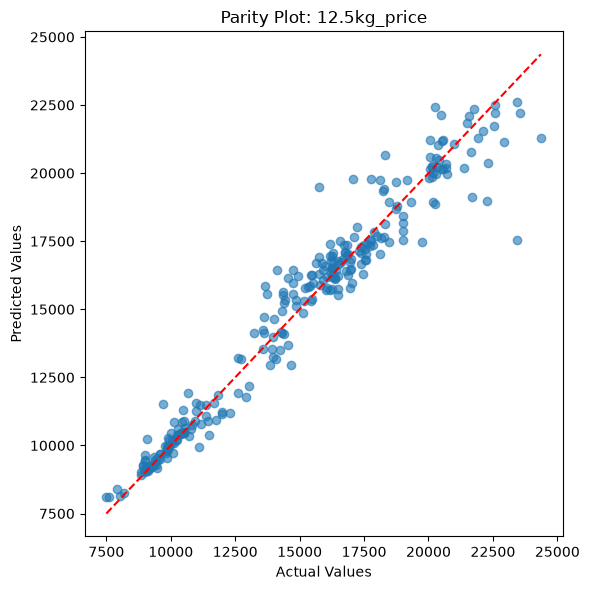

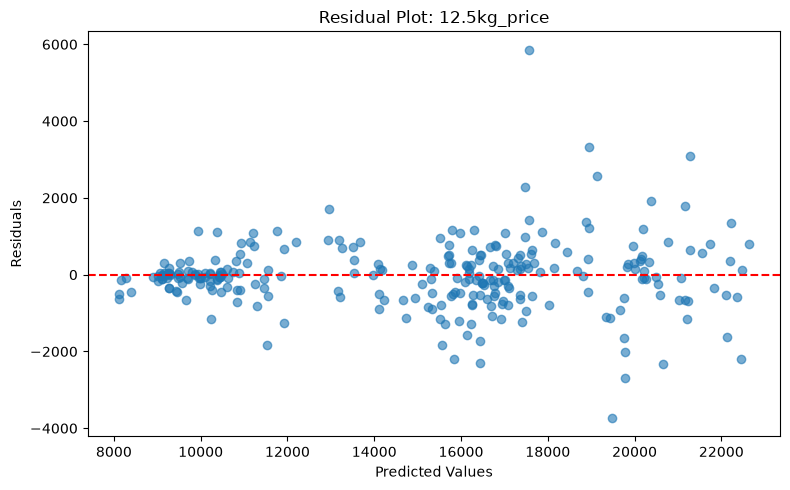

All plots generated and saved successfully to plot_images/.


In [11]:
# Create plot_images directory
os.makedirs('plot_images', exist_ok=True)

# 1. Feature Importance Bar Chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(15))
plt.title(f'Top 15 Feature Importances ({best_model_name})')
plt.tight_layout()
plt.savefig('plot_images/feature_importance.png')
plt.show()

# 2. Parity Plots & Residual Plots for each target
for i, col in enumerate(target_cols):
    y_true = y_test.iloc[:, i]
    y_p = y_pred[:, i]
    
    # Parity Plot
    plt.figure(figsize=(6, 6))
    plt.scatter(y_true, y_p, alpha=0.6)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
    plt.xlabel('Actual Values')
    plt.ylabel('Predicted Values')
    plt.title(f'Parity Plot: {col}')
    plt.tight_layout()
    plt.savefig(f'plot_images/parity_plot_{col}.png')
    plt.show()
    
    # Residual Plot
    residuals = y_true - y_p
    plt.figure(figsize=(8, 5))
    plt.scatter(y_p, residuals, alpha=0.6)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Predicted Values')
    plt.ylabel('Residuals')
    plt.title(f'Residual Plot: {col}')
    plt.tight_layout()
    plt.savefig(f'plot_images/residual_plot_{col}.png')
    plt.show()

print('All plots generated and saved successfully to plot_images/.')

## 7. Model Export for Web Deployment (Streamlit)
We export the trained model and feature metadata into pickle/joblib files so they can be loaded instantly by a Streamlit web application.

In [12]:
import joblib

# Save the final trained model
joblib.dump(final_model, 'lpg_model.pkl')

# Save metadata needed for the frontend application
metadata = {
    'features': best_variant_features,
    'target_cols': target_cols
}
joblib.dump(metadata, 'model_metadata.pkl')

print('Model and metadata successfully saved to lpg_model.pkl and model_metadata.pkl!')

Model and metadata successfully saved to lpg_model.pkl and model_metadata.pkl!
